# Assignment Beta - Question 2: Experiments and Evaluation

**Student ID:** 23k-6005  
**Base model:** Qwen2.5-1.5B-Instruct  
**Training hardware:** NVIDIA RTX 4050 Laptop GPU

This notebook organizes and checks the results of the experiments I ran locally using `q2_prepare_data_clean.py` and `q2_train_eval_clean.py`. It uses the saved results, so opening it **does not retrain the models**. 

## 1. Data and training setup

I selected 2,000 function-call examples from Glaive, keeping 1,800 for training and 200 for testing. I removed duplicate user prompts before splitting the data. The test prompts were not used for training.

Every method used the same Qwen model, random seed 42, one epoch, learning rate 0.0002, effective batch size 8, cosine schedule and the same target modules. The main difference was the adapter method; QLoRA also used 4-bit NF4 base weights.

The commands were run on my laptop. Their results were saved to `q2_results_clean.csv` and prediction JSONL files.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

folder = Path.cwd()
print('Working folder:', folder)

Working folder: /mnt/data


In [2]:
recorded_results = json.loads('[\n  {\n    "run": "base",\n    "method": "base",\n    "rank": "-",\n    "trainable_params": "0",\n    "total_params": "1543714304",\n    "trainable_pct": "0",\n    "peak_mem_gb": "0.0",\n    "train_minutes": "0.0",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "187/200",\n    "eval_seconds": "80.87",\n    "seconds_per_test_query": "0.404",\n    "batched_generated_tps": "68.78"\n  },\n  {\n    "run": "lora_r8",\n    "method": "lora",\n    "rank": "8",\n    "trainable_params": "9232384",\n    "total_params": "1552946688",\n    "trainable_pct": "0.5945",\n    "peak_mem_gb": "4.13",\n    "train_minutes": "11.5",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "192/200",\n    "eval_seconds": "199.58",\n    "seconds_per_test_query": "0.998",\n    "batched_generated_tps": "27.87"\n  },\n  {\n    "run": "qlora_r8",\n    "method": "qlora",\n    "rank": "8",\n    "trainable_params": "9232384",\n    "total_params": "1552946688",\n    "trainable_pct": "0.5945",\n    "peak_mem_gb": "2.81",\n    "train_minutes": "16.3",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "191/200",\n    "eval_seconds": "171.03",\n    "seconds_per_test_query": "0.855",\n    "batched_generated_tps": "32.69"\n  },\n  {\n    "run": "dora_r8",\n    "method": "dora",\n    "rank": "8",\n    "trainable_params": "9877504",\n    "total_params": "1553591808",\n    "trainable_pct": "0.6358",\n    "peak_mem_gb": "4.14",\n    "train_minutes": "57.9",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "191/200",\n    "eval_seconds": "1123.6",\n    "seconds_per_test_query": "5.618",\n    "batched_generated_tps": "4.94"\n  },\n  {\n    "run": "adalora_r12to8",\n    "method": "adalora",\n    "rank": "8",\n    "trainable_params": "13851124",\n    "total_params": "1557565428",\n    "trainable_pct": "0.8893",\n    "peak_mem_gb": "4.4",\n    "train_minutes": "16.8",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "187/200",\n    "eval_seconds": "138.29",\n    "seconds_per_test_query": "0.691",\n    "batched_generated_tps": "40.22"\n  },\n  {\n    "run": "lora_r4",\n    "method": "lora",\n    "rank": "4",\n    "trainable_params": "4616192",\n    "total_params": "1548330496",\n    "trainable_pct": "0.2981",\n    "peak_mem_gb": "4.06",\n    "train_minutes": "17.5",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "191/200",\n    "eval_seconds": "134.52",\n    "seconds_per_test_query": "0.673",\n    "batched_generated_tps": "41.26"\n  },\n  {\n    "run": "lora_r16",\n    "method": "lora",\n    "rank": "16",\n    "trainable_params": "18464768",\n    "total_params": "1562179072",\n    "trainable_pct": "1.182",\n    "peak_mem_gb": "4.26",\n    "train_minutes": "31.9",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "192/200",\n    "eval_seconds": "440.46",\n    "seconds_per_test_query": "2.202",\n    "batched_generated_tps": "12.61"\n  },\n  {\n    "run": "lora_r32",\n    "method": "lora",\n    "rank": "32",\n    "trainable_params": "36929536",\n    "total_params": "1580643840",\n    "trainable_pct": "2.3364",\n    "peak_mem_gb": "4.58",\n    "train_minutes": "23.9",\n    "json_valid": "200/200",\n    "tool_acc": "200/200",\n    "full_match": "191/200",\n    "eval_seconds": "166.42",\n    "seconds_per_test_query": "0.832",\n    "batched_generated_tps": "33.53"\n  }\n]' )
recorded_manifest = json.loads('{\n  "seed": 42,\n  "model": "Qwen/Qwen2.5-1.5B-Instruct",\n  "max_sequence_length": 640,\n  "source": "glaiveai/glaive-function-calling-v2",\n  "records_parsed": 45584,\n  "unique_user_prompts_selected": 2000,\n  "duplicates_skipped_before_selection": 3683,\n  "overlength_skipped_before_selection": 1,\n  "train_count": 1800,\n  "test_count": 200,\n  "train_sha256": "825d6261003a1d1dd96b5ba6ff1816728ee1e8065394f2cc6c3c5cf237966a4b",\n  "test_sha256": "4c0f81161ae64f39db5a62f106d9088b7a6e2a4c3be9d99a3d8f9477dfe886bd",\n  "selection_rule": "Shuffled records; unique normalized USER prompt; first valid function call; full prompt+target <=640 tokens; target <=256 tokens."\n}' )
results_file = folder / 'q2_results_clean.csv'
if results_file.exists():
    data = pd.read_csv(results_file, dtype={'rank': str})
    print('Source: local q2_results_clean.csv')
else:
    data = pd.DataFrame(recorded_results)
    print('Source: recorded results embedded in this notebook')
assert len(data) == 8
print('Selected examples:', recorded_manifest['unique_user_prompts_selected'])
print('Training / test:', recorded_manifest['train_count'], '/', recorded_manifest['test_count'])
print('Seed:', recorded_manifest['seed'])
display(data[['run', 'method', 'rank', 'trainable_params', 'trainable_pct', 'peak_mem_gb', 'train_minutes', 'json_valid', 'tool_acc', 'full_match']])

Source: local q2_results_clean.csv
Selected examples: 2000
Training / test: 1800 / 200
Seed: 42


,run,method,rank,trainable_params,trainable_pct,peak_mem_gb,train_minutes,json_valid,tool_acc,full_match
0,base,base,-,0,0.0000,0.00,0.0,200/200,200/200,187/200
1,lora_r8,lora,8,9232384,0.5945,4.13,11.5,200/200,200/200,192/200
2,qlora_r8,qlora,8,9232384,0.5945,2.81,16.3,200/200,200/200,191/200
3,dora_r8,dora,8,9877504,0.6358,4.14,57.9,200/200,200/200,191/200
4,adalora_r12to8,adalora,8,13851124,0.8893,4.40,16.8,200/200,200/200,187/200
5,lora_r4,lora,4,4616192,0.2981,4.06,17.5,200/200,200/200,191/200
6,lora_r16,lora,16,18464768,1.1820,4.26,31.9,200/200,200/200,192/200
7,lora_r32,lora,32,36929536,2.3364,4.58,23.9,200/200,200/200,191/200


## 2. Five main experiments

I compared the original model with LoRA, QLoRA, DoRA and AdaLoRA. `valid JSON` means the response could be parsed. `Correct tool` means the function name matched. `Full match` means both the function name and every argument matched.

In [3]:
main_order = ['base', 'lora_r8', 'qlora_r8', 'dora_r8', 'adalora_r12to8']
main = data.set_index('run').loc[main_order].reset_index().copy()
for metric in ['json_valid', 'tool_acc', 'full_match']:
    main[metric + '_pct'] = main[metric].apply(lambda s: 100 * int(str(s).split('/')[0]) / int(str(s).split('/')[1]))
display(main[['run', 'trainable_params', 'trainable_pct', 'peak_mem_gb', 'train_minutes', 'json_valid_pct', 'tool_acc_pct', 'full_match_pct', 'seconds_per_test_query']].round(3))
best = main.sort_values(['full_match_pct','trainable_params'], ascending=[False, True]).iloc[0]
print('Best exact-match method:', best['run'], f"({best['full_match_pct']:.1f}%)")
print('Lowest reported adapter memory:', main[main['run'] != 'base'].sort_values('peak_mem_gb').iloc[0]['run'])

,run,trainable_params,trainable_pct,peak_mem_gb,train_minutes,json_valid_pct,tool_acc_pct,full_match_pct,seconds_per_test_query
0,base,0,0.000,0.00,0.0,100.0,100.0,93.5,0.404
1,lora_r8,9232384,0.594,4.13,11.5,100.0,100.0,96.0,0.998
2,qlora_r8,9232384,0.594,2.81,16.3,100.0,100.0,95.5,0.855
3,dora_r8,9877504,0.636,4.14,57.9,100.0,100.0,95.5,5.618
4,adalora_r12to8,13851124,0.889,4.40,16.8,100.0,100.0,93.5,0.691


Best exact-match method: lora_r8 (96.0%)
Lowest reported adapter memory: qlora_r8


**Observation:** Every method selected the correct tool in all 200 test cases. LoRA at rank 8 had the highest exact-call score: 192/200 (96%). QLoRA used the least allocated GPU training memory (2.81 GB). These results are from this one test split and do not prove general performance on real e-commerce requests.

## 3. LoRA rank experiment

I compared ranks 4, 8, 16 and 32. The original rank-8 experiment is reused rather than trained again. Both tool accuracy and full-match accuracy are shown because all four ranks selected the correct function every time.

,rank_num,trainable_params,trainable_pct,peak_mem_gb,tool_accuracy,full_match_accuracy
0,4,4616192,0.2981,4.06,100.0,95.5
1,8,9232384,0.5945,4.13,100.0,96.0
2,16,18464768,1.1820,4.26,100.0,96.0
3,32,36929536,2.3364,4.58,100.0,95.5


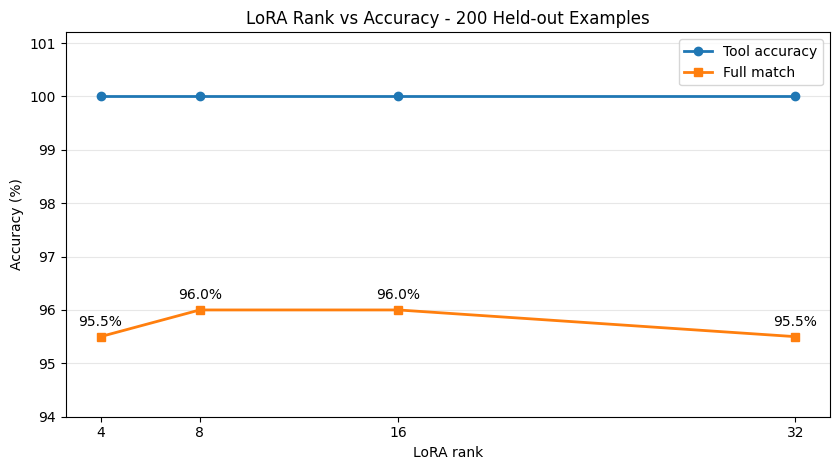

In [4]:
rank_order = ['lora_r4', 'lora_r8', 'lora_r16', 'lora_r32']
ranks = data.set_index('run').loc[rank_order].reset_index().copy()
ranks['rank_num'] = ranks['rank'].astype(int)
ranks['tool_accuracy'] = ranks['tool_acc'].map(lambda s: 100*int(str(s).split('/')[0])/int(str(s).split('/')[1]))
ranks['full_match_accuracy'] = ranks['full_match'].map(lambda s: 100*int(str(s).split('/')[0])/int(str(s).split('/')[1]))
display(ranks[['rank_num','trainable_params','trainable_pct','peak_mem_gb','tool_accuracy','full_match_accuracy']])
fig, ax = plt.subplots(figsize=(8.5,4.8))
ax.plot(ranks['rank_num'], ranks['tool_accuracy'], marker='o', linewidth=2, label='Tool accuracy')
ax.plot(ranks['rank_num'], ranks['full_match_accuracy'], marker='s', linewidth=2, label='Full match')
ax.set_xticks([4,8,16,32])
ax.set_ylim(94,101.2)
ax.set_xlabel('LoRA rank')
ax.set_ylabel('Accuracy (%)')
ax.set_title('LoRA Rank vs Accuracy - 200 Held-out Examples')
ax.grid(axis='y', alpha=0.3)
ax.legend()
for x,y in zip(ranks['rank_num'],ranks['full_match_accuracy']):
    ax.annotate(f'{y:.1f}%', (x,y), xytext=(0,8), textcoords='offset points', ha='center')
fig.tight_layout()
fig.savefig(folder/'Q2_LoRA_Rank_Accuracy_Notebook.png',dpi=180)
plt.show()

**Rank conclusion:** Rank 8 and rank 16 both got 192/200 full matches. Rank 16 had twice the trainable parameters. Rank 32 did not improve the result. Rank 8 is the more practical choice among the configurations tied for the best exact-match score.

## 4. Five actual wrong predictions from LoRA rank 8

These records come from `preds_lora_r8_clean.jsonl`, saved after evaluating the best adapter on the 200 test examples.

In [5]:
recorded_failures = json.loads('[\n  {\n    "user": "I am looking for a mystery book by Agatha Christie.",\n    "target": "{\\"name\\": \\"search_books\\", \\"arguments\\": {\\"query\\": \\"mystery\\", \\"author\\": \\"Agatha Christie\\"}}",\n    "pred": "{\\"name\\": \\"search_books\\", \\"arguments\\": {\\"query\\": \\"\\", \\"author\\": \\"Agatha Christie\\", \\"genre\\": \\"mystery\\"}}",\n    "valid": 1,\n    "tool_ok": 1,\n    "full": 0\n  },\n  {\n    "user": "I\'m looking for a Mexican recipe that uses chicken and tomatoes. I\'m also lactose intolerant.",\n    "target": "{\\"name\\": \\"search_recipes\\", \\"arguments\\": {\\"cuisine\\": \\"Mexican\\", \\"ingredients\\": [\\"chicken\\", \\"tomatoes\\"], \\"dietary_restrictions\\": [\\"lactose intolerant\\"]}}",\n    "pred": "{\\"name\\": \\"search_recipes\\", \\"arguments\\": {\\"cuisine\\": \\"Mexican\\", \\"ingredients\\": [\\"chicken\\", \\"tomatoes\\"], \\"dietary_restrictions\\": [\\"lactose\\"]}}",\n    "valid": 1,\n    "tool_ok": 1,\n    "full": 0\n  },\n  {\n    "user": "I am looking for a book but I can\'t remember the full title. It\'s something like \\"To Kill a\\".",\n    "target": "{\\"name\\": \\"search_book\\", \\"arguments\\": {\\"query\\": \\"To Kill a\\"}}",\n    "pred": "{\\"name\\": \\"search_book\\", \\"arguments\\": {\\"query\\": \\"To Kill\\"}}",\n    "valid": 1,\n    "tool_ok": 1,\n    "full": 0\n  },\n  {\n    "user": "Hi, I need to get from New York to Los Angeles. Can you help me with the directions?",\n    "target": "{\\"name\\": \\"get_directions\\", \\"arguments\\": {\\"origin\\": \\"New York\\", \\"destination\\": \\"Los Angeles\\", \\"mode\\": \\"driving\\"}}",\n    "pred": "{\\"name\\": \\"get_directions\\", \\"arguments\\": {\\"origin\\": \\"New York\\", \\"destination\\": \\"Los Angeles\\"}}",\n    "valid": 1,\n    "tool_ok": 1,\n    "full": 0\n  },\n  {\n    "user": "I\'m looking for a good Italian restaurant in New York. Can you help?",\n    "target": "{\\"name\\": \\"search_restaurants\\", \\"arguments\\": {\\"location\\": \\"New York\\", \\"cuisine\\": \\"Italian\\", \\"price_range\\": \\"medium\\"}}",\n    "pred": "{\\"name\\": \\"search_restaurants\\", \\"arguments\\": {\\"location\\": \\"New York\\", \\"cuisine\\": \\"Italian\\"}}",\n    "valid": 1,\n    "tool_ok": 1,\n    "full": 0\n  }\n]' )
prediction_file = folder / 'preds_lora_r8_clean.jsonl'
if prediction_file.exists():
    predictions = [json.loads(line) for line in prediction_file.read_text(encoding='utf-8').splitlines() if line.strip()]
    assert len(predictions) == 200
    bad = [r for r in predictions if int(r['full']) == 0]
    assert len(bad) == 8
    shown = bad[:5]
    print('Source: 200 saved predictions; mistakes:', len(bad))
else:
    shown = recorded_failures
    print('Source: five recorded errors embedded in this notebook')
for number, example in enumerate(shown,1):
    print(f'\nError {number}')
    print('Customer:', example['user'])
    print('Expected:', example['target'])
    print('Predicted:', example['pred'])
    print('Correct tool:', bool(example['tool_ok']), '| Exact match:', bool(example['full']))

Source: 200 saved predictions; mistakes: 8

Error 1
Customer: I am looking for a mystery book by Agatha Christie.
Expected: {"name": "search_books", "arguments": {"query": "mystery", "author": "Agatha Christie"}}
Predicted: {"name": "search_books", "arguments": {"query": "", "author": "Agatha Christie", "genre": "mystery"}}
Correct tool: True | Exact match: False

Error 2
Customer: I'm looking for a Mexican recipe that uses chicken and tomatoes. I'm also lactose intolerant.
Expected: {"name": "search_recipes", "arguments": {"cuisine": "Mexican", "ingredients": ["chicken", "tomatoes"], "dietary_restrictions": ["lactose intolerant"]}}
Predicted: {"name": "search_recipes", "arguments": {"cuisine": "Mexican", "ingredients": ["chicken", "tomatoes"], "dietary_restrictions": ["lactose"]}}
Correct tool: True | Exact match: False

Error 3
Customer: I am looking for a book but I can't remember the full title. It's something like "To Kill a".
Expected: {"name": "search_book", "arguments": {"query

**Error pattern:** The five examples have the correct function name and valid JSON. The mistakes are about arguments: missing fields, shortened values or values moved to a different field. In a real service, a JSON-schema check and clarification step could prevent incorrect calls.

## 5. Check data files and experiment settings

The manifest was created when the clean training and test files were selected. If both files are present, this cell verifies their checksums. It does not change the data.

In [6]:
import hashlib
manifest_file = folder / 'q2_data_manifest.json'
manifest = json.loads(manifest_file.read_text(encoding='utf-8')) if manifest_file.exists() else recorded_manifest
for filename, expected in [('train.jsonl', manifest['train_sha256']), ('test.jsonl', manifest['test_sha256'])]:
    path = folder / filename
    if path.exists():
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        print(filename, 'verified' if digest == expected else 'CHECKSUM MISMATCH')
    else:
        print(filename, 'not available; saved manifest retained')
print('Source dataset:', manifest['source'])
print('Model:', manifest['model'])
print('Maximum sequence length:', manifest['max_sequence_length'])

train.jsonl not available; saved manifest retained
test.jsonl not available; saved manifest retained
Source dataset: glaiveai/glaive-function-calling-v2
Model: Qwen/Qwen2.5-1.5B-Instruct
Maximum sequence length: 640


## 6. Re-run experiments only if needed

The main runs were already completed locally, and the outputs above are the saved measurements. The scripts `q2_prepare_data_clean.py` and `q2_train_eval_clean.py` contain the dataset processing and PEFT training implementation. The commands below will not run unless `RUN_FULL_TRAINING` is changed to `True` on a CUDA-enabled computer. Repeating the runs is **not needed** for ordinary grading or review of this notebook.

In [7]:
import subprocess
import sys
RUN_FULL_TRAINING = False
commands = [
    ['--method','base'],
    ['--method','lora','--rank','8'],
    ['--method','qlora','--rank','8'],
    ['--method','dora','--rank','8'],
    ['--method','adalora','--rank','8'],
    ['--method','lora','--rank','4'],
    ['--method','lora','--rank','16'],
    ['--method','lora','--rank','32']
]
if RUN_FULL_TRAINING:
    assert (folder/'q2_train_eval_clean.py').exists()
    assert (folder/'train.jsonl').exists() and (folder/'test.jsonl').exists()
    for arguments in commands:
        subprocess.run([sys.executable, str(folder/'q2_train_eval_clean.py'), *arguments], check=True)
else:
    print('Full training skipped. Showing the eight recorded experiments instead.')

Full training skipped. Showing the eight recorded experiments instead.


## 7. Summary

LoRA rank 8 is the preferred method for this test. It gave the highest exact-match accuracy without using as much training memory or as many adapter parameters as some of the alternatives. QLoRA is a reasonable option when GPU memory is the main limit. All results came from a general function-calling dataset, so the model still needs testing with the real refund, delivery and order-status tools before deployment.

**AI-use declaration:** ChatGPT/Codex helped draft and review the scripts, organize this notebook, create the charts, and check calculations. The model training and evaluation were run on the student's laptop. The numeric results and error examples are from the saved experiment files.